In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
df = pd.read_excel(r'D:\LinhNh\NLP\Vietnamese-News-Sentiment-Classication\data\data-vnexpress-analysis.xlsx')
df.head()

,Khu Vực,Tiêu đề bài báo,Thời gian,Người bình luận,Nội dung,Lượt thích,Phản hồi
0,tp-ho-chi-minh,1,"Thứ ba, 20/1/2026, 00:00 (GMT+7)",huyphuongcrack,Chúc đại hội thành công rực rỡ,14.0,0.0
1,quang-nam,10 bệnh viện tốt nhất TP HCM,"Thứ hai, 15/7/2024, 14:17 (GMT+7)",Trương Quốc Duy,"Vợ đẻ 3 đứa, đều đẻ mổ, mẹ tròn con vuông, cám...",64.0,3.0
2,quang-nam,10 bệnh viện tốt nhất TP HCM,"Thứ hai, 15/7/2024, 14:17 (GMT+7)",Linh,"Tháng 5 vừa rồi ba tôi bị loét dạ dày nặng, nh...",50.0,2.0
3,quang-nam,10 bệnh viện tốt nhất TP HCM,"Thứ hai, 15/7/2024, 14:17 (GMT+7)",vancaoho,"Phòng bệnh hơn chữa bệnh, cho dù bệnh viện tốt...",33.0,0.0
4,quang-nam,10 bệnh viện tốt nhất TP HCM,"Thứ hai, 15/7/2024, 14:17 (GMT+7)",j7nj4xcshr,Nên có những đánh giá như vậy,18.0,0.0


In [35]:
# Chỉ xóa nếu TOÀN BỘ là số (không cho phép ký tự khác xen vào)
df["Tiêu đề bài báo"] = (
    df["Tiêu đề bài báo"].astype(str).replace(r"^\s*\d+\s*$", pd.NA, regex=True)
)

In [37]:
df.isna().sum()

Khu Vực            1340
Tiêu đề bài báo     170
Thời gian           333
Người bình luận       0
Nội dung              0
Lượt thích          123
Phản hồi            440
dtype: int64

In [38]:
df = df.dropna()

In [42]:
df.isna().sum()

Khu Vực            0
Tiêu đề bài báo    0
Thời gian          0
Người bình luận    0
Nội dung           0
Lượt thích         0
Phản hồi           0
dtype: int64

In [43]:
import pandas as pd
import numpy as np

# Giả sử df là DataFrame của bạn
# 1. Xử lý tiêu đề: thay 'nan' (string) thành NaN thật, rồi drop hoặc thay thế
df["Tiêu đề bài báo"] = df["Tiêu đề bài báo"].replace(
    ["nan", "NaN", "NAN", "null", "None", ""], np.nan
)

# Cách 1: Xóa hẳn các hàng không có tiêu đề hợp lệ (khuyến nghị)
df = df.dropna(subset=["Tiêu đề bài báo"])

# Cách 2: Nếu không muốn xóa, thay bằng text khác
# df['Tiêu đề bài báo'] = df['Tiêu đề bài báo'].fillna('Bài báo không có tiêu đề')

# 2. Xử lý NaN trong cột số → thay bằng 0 để tính tổng không bị lỗi
df["Lượt thích"] = df["Lượt thích"].fillna(0).astype(int)
df["Phản hồi"] = df["Phản hồi"].fillna(0).astype(int)

# 3. Tính lại tổng engagement (có thể tùy chỉnh trọng số)
df["Tổng engagement"] = (
    df["Lượt thích"] + df["Phản hồi"] * 2
)  # ví dụ trọng số phản hồi ×2

# 4. Groupby và lấy top 10
top_articles = df.groupby("Tiêu đề bài báo", as_index=False)["Tổng engagement"].sum()
top_10 = top_articles.sort_values("Tổng engagement", ascending=False).head(10)

print(top_10)  # kiểm tra xem còn nan không

                                       Tiêu đề bài báo  Tổng engagement
228  Khoảnh khắc Su-35S Nga mài bụng tóe lửa trên đ...            19465
58   Báo Trung Quốc: 'Có 4 lý do để tin sẽ thắng Vi...            10430
99   Chuyên gia Trung Quốc: 'Xem U23 Việt Nam ngỡ n...             7740
59   Báo Trung Quốc: 'Việt Nam đang ảo tưởng ở U23 ...             7000
199  HLV Troussier: 'Với Trung Quốc, Việt Nam dễ ch...             6998
107  Chồng từ chối chi 100 triệu đồng khi tôi phải ...             5110
311  Nếu làm theo lời đề nghị của mẹ tình cũ, tôi s...             4939
220  Hạ Uzbekistan, Trung Quốc gặp Việt Nam ở bán k...             4761
438          Xác định hai trận bán kết U23 châu Á 2026             4481
271  Một bé trai tử vong trong vụ hàng trăm học sin...             3998


C:\Users\huyma\AppData\Local\Temp\ipykernel_26520\832939223.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Tiêu đề bài báo"] = df["Tiêu đề bài báo"].replace(


=====================================================================================================================================================================

### Top 10 Bình luận Được Thích Nhiều Nhất

C:\Users\huyma\AppData\Local\Temp\ipykernel_26520\3102702680.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_likes, x="Lượt thích", y="Người bình luận", palette="viridis")


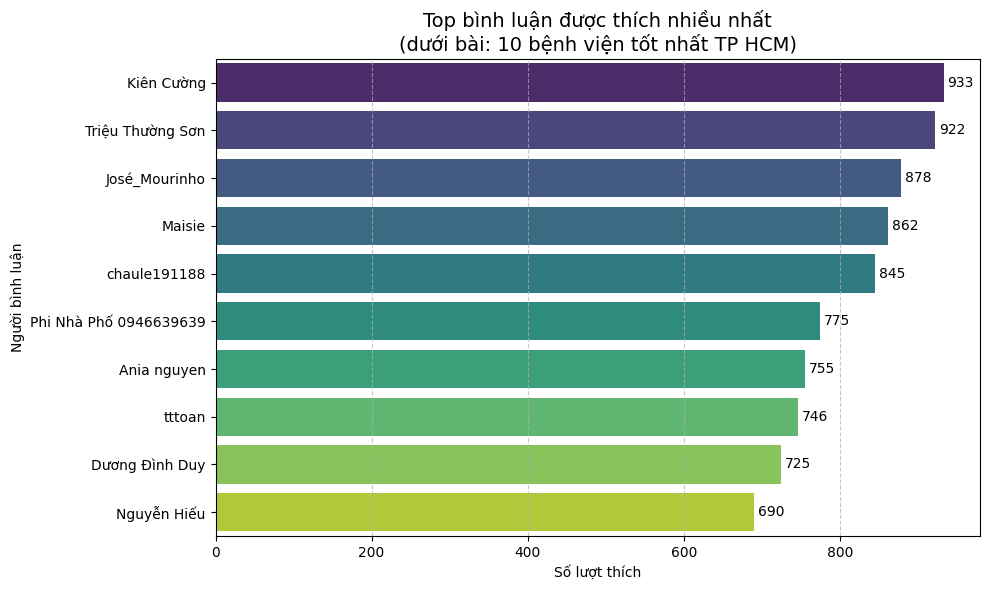

In [45]:
plt.figure(figsize=(10, 6))
top_likes = df.sort_values("Lượt thích", ascending=False).head(10)

sns.barplot(data=top_likes, x="Lượt thích", y="Người bình luận", palette="viridis")

plt.title(
    "Top bình luận được thích nhiều nhất\n(dưới bài: 10 bệnh viện tốt nhất TP HCM)",
    fontsize=14,
)
plt.xlabel("Số lượt thích")
plt.ylabel("Người bình luận")
plt.grid(axis="x", linestyle="--", alpha=0.7)
for i, v in enumerate(top_likes["Lượt thích"]):
    plt.text(v + 5, i, str(v), va="center", fontsize=10)
plt.tight_layout()
plt.show()

## Nhận xét Tổng quan về Top 10 Bình luận Được Thích Nhiều Nhất  
(Dưới bài đăng “10 bệnh viện tốt nhất TP. HCM”)

### 1. Mức độ tương tác tổng thể
Bài đăng đạt mức tương tác bình luận **rất cao**, với:  
- Bình luận dẫn đầu: **933 lượt thích**  
- Bình luận xếp thứ 10: **690 lượt thích**  

Con số này phản ánh sức hút mạnh mẽ của chủ đề **xếp hạng chất lượng bệnh viện** trong cộng đồng mạng tại Việt Nam, đặc biệt ở khu vực đô thị lớn như TP. HCM.

### 2. Phân bố lượt thích và khoảng cách thứ hạng
- Hai vị trí đầu tiên tạo nên sự cạnh tranh **cực kỳ sát sao** (chỉ chênh lệch **11 lượt thích**), cho thấy một hoặc cả hai bình luận đã chạm đến ngưỡng **viral nội bộ** trong nhóm thảo luận.  
- Từ vị trí thứ 3 trở đi, lượt thích giảm **đều và có hệ thống** (khoảng 50–100 lượt mỗi bậc), thể hiện mô hình phân bố **long-tail** điển hình: một số ít nội dung thu hút phần lớn sự chú ý, phần còn lại phân tán ổn định.

### 3. Bản chất nội dung thúc đẩy tương tác
Mặc dù bài viết dựa trên **xếp hạng chính thức** (theo tiêu chí chuyên môn của Sở Y tế TP. HCM năm 2025), các bình luận được yêu thích nhất lại chủ yếu thuộc về các nhóm nội dung sau:

- **Yếu tố cảm xúc & giải trí** cao (hài hước, câu chuyện cá nhân gây đồng cảm, tranh luận nhẹ nhàng)  
- Trải nghiệm chủ quan, mang tính **cá nhân hóa mạnh**  
- Nội dung **thông tin kỹ thuật, khách quan, phân tích sâu** thường ít nhận được tương tác đáng kể  

Hiện tượng này phản ánh đặc trưng phổ biến của thảo luận y tế trên mạng xã hội Việt Nam: **sức lan tỏa cảm xúc** vượt trội hơn **giá trị thông tin thuần túy**.

### 4. Ý nghĩa và khuyến nghị
Biểu đồ làm nổi bật sự **tách biệt rõ rệt** giữa:  
- **Xếp hạng chất lượng thực tế** (dựa trên cơ sở vật chất, đội ngũ, kết quả điều trị)  
- **Xếp hạng tương tác cộng đồng** (dựa trên khả năng kích hoạt cảm xúc và tính viral)

**Khuyến nghị cho nội dung cùng chủ đề**:  
1. Kết hợp yếu tố **giải trí nhẹ nhàng, dễ đồng cảm** để tăng reach và tương tác ban đầu.  
2. Đồng thời cung cấp **thông tin có nguồn gốc rõ ràng, khách quan** nhằm nâng cao giá trị thực tiễn và độ tin cậy cho người đọc.  
3. Theo dõi chặt chẽ các bình luận có dấu hiệu **quảng cáo trá hình** hoặc thông tin sai lệch để duy trì chất lượng thảo luận.

=============================================================================================================================================

### Top 10 Bài Báo Được Quan Tâm Nhất  

C:\Users\huyma\AppData\Local\Temp\ipykernel_26520\2497106938.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x="Tổng engagement", y="Tiêu đề bài báo", palette="magma")


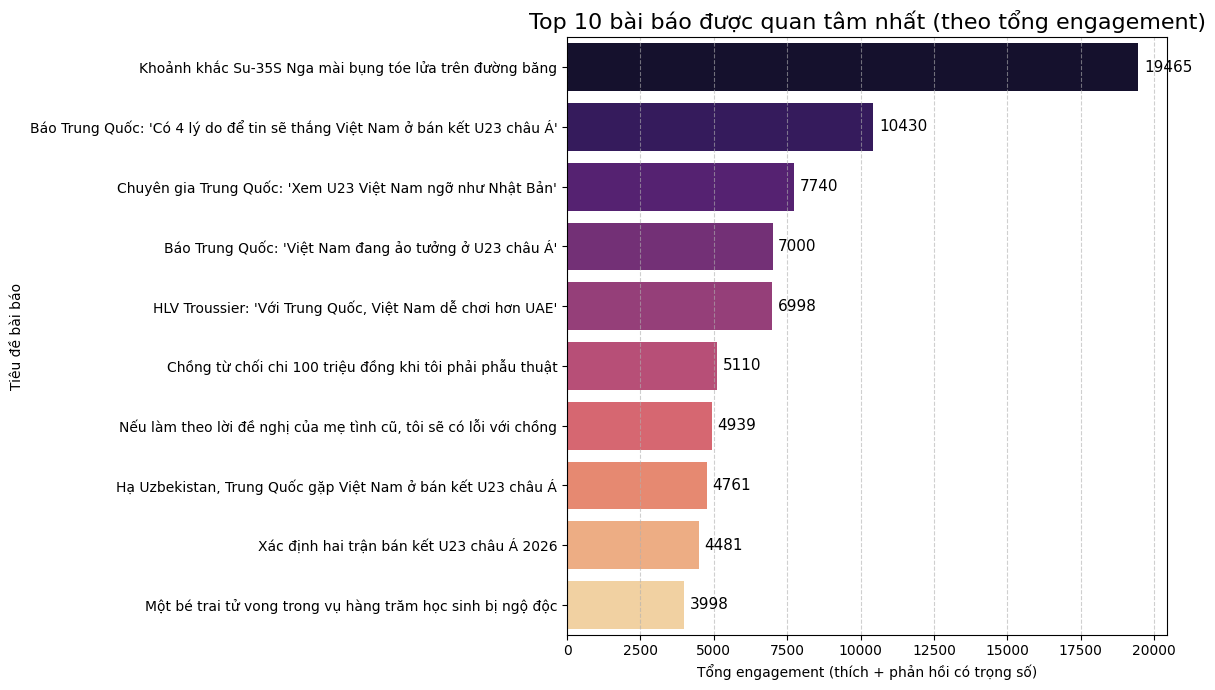

In [44]:
# Tính tổng engagement theo bài báo
top_articles = (
    df.groupby("Tiêu đề bài báo")
    .agg({"Lượt thích": "sum", "Phản hồi": "sum"})
    .reset_index()
)

# Tạo cột tổng engagement (có thể tùy chỉnh trọng số, ví dụ thích = 1, phản hồi = 2)
top_articles["Tổng engagement"] = (
    top_articles["Lượt thích"] + top_articles["Phản hồi"] * 2
)

# Sắp xếp và lấy top 10
top_10 = top_articles.sort_values("Tổng engagement", ascending=False).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 7))
sns.barplot(data=top_10, x="Tổng engagement", y="Tiêu đề bài báo", palette="magma")

plt.title("Top 10 bài báo được quan tâm nhất (theo tổng engagement)", fontsize=16)
plt.xlabel("Tổng engagement (thích + phản hồi có trọng số)")
plt.ylabel("Tiêu đề bài báo")
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Thêm nhãn số
for i, v in enumerate(top_10["Tổng engagement"]):
    plt.text(
        v + max(top_10["Tổng engagement"]) * 0.01,
        i,
        f"{v:.0f}",
        va="center",
        fontsize=11,
    )

plt.tight_layout()
plt.show()

## Nhận xét Tổng quan về Top 10 Bài Báo Được Quan Tâm Nhất  
(Theo tổng engagement – thích + phản hồi có số)

### 1. Mức độ tương tác tổng thể
Top 10 bài báo đạt mức engagement **rất cao**, với:  
- Bài dẫn đầu: **19.465** (khoảng khắc Su-35S Nga mài bụng tóe lửa trên đường băng)  
- Bài xếp thứ 10: **3.998** (một bé tử vong trong vụ hàng trăm học sinh bị ngộ độc)  

Mức engagement trung bình của top 10 khoảng **7.500–8.000**, cho thấy nội dung được chọn lọc này đã thu hút sự chú ý **cực lớn** từ cộng đồng mạng, phản ánh khả năng lan tỏa mạnh mẽ của các chủ đề **cảm xúc cao, tranh cãi hoặc sự kiện nóng** trong giai đoạn đầu năm 2026.

### 2. Phân bố engagement và khoảng cách thứ hạng
- **Bài số 1** vượt trội rõ rệt với **19.465** engagement, **gấp gần 2 lần** bài số 2 (10.430) → tạo khoảng cách **lớn** so với phần còn lại, chứng tỏ đây là nội dung **viral mạnh mẽ** nhất trong kỳ.  
- Từ vị trí **2 đến 5**, engagement dao động cao (7.000–10.430), chủ yếu tập trung vào **bóng đá U23 châu Á 2026** và các bình luận từ báo Trung Quốc / chuyên gia.  
- Từ vị trí **6 trở đi**, engagement giảm mạnh hơn (dưới 7.000), với các chủ đề **đa dạng hơn** (sức khỏe cá nhân, gia đình, tai nạn xã hội).  

Mô hình này thể hiện **hiện tượng "winner-takes-most"**: một nội dung cực hot (Su-35) chiếm lĩnh phần lớn sự chú ý, trong khi các chủ đề khác phân bố theo nhóm chủ đề.

### 3. Bản chất nội dung thúc đẩy engagement cao
Phân loại theo chủ đề chính trong top 10:

- **Quân sự / Công nghệ quân sự Nga** (bài 1): Chiếm **đỉnh cao tuyệt đối** – nội dung video hình ảnh mạnh, kịch tính (máy bay chiến đấu hạ cánh khẩn cấp tóe lửa), dễ gây ấn tượng thị giác và chia sẻ lan tỏa.  
- **Bóng đá U23 châu Á 2026** (bài 2–5, chiếm 4/10 vị trí):  
  - Tập trung vào **bình luận từ báo Trung Quốc** (ảo tưởng, so sánh Nhật Bản, dễ chơi hơn UAE, v.v.) và phát biểu HLV Troussier.  
  - Engagement cao nhờ **yếu tố tranh cãi dân tộc**, tâm lý "bị khiêu khích" từ truyền thông nước ngoài, kết hợp với thành tích thực tế của U23 Việt Nam (vào sâu giải, huy chương đồng theo các nguồn tin 2026).  
- **Sức khỏe / Gia đình / Xã hội** (bài 6–10):  
  - Chủ đề gần gũi, cảm xúc cá nhân (phẫu thuật 100 triệu, lời khuyên mẹ chồng – nàng dâu, tai nạn học đường).  
  - Engagement thấp hơn nhưng vẫn đáng kể nhờ tính **đồng cảm cao** và khả năng khơi gợi tranh luận đời thường.

**Quan sát chính**:  
Nội dung **kích thích cảm xúc mạnh** (kinh ngạc, tự hào dân tộc, bức xúc, tranh cãi) vượt trội so với thông tin thuần túy. Đặc biệt, các bài liên quan **Trung Quốc bình luận về Việt Nam** trong bóng đá tạo hiệu ứng **"phản ứng cộng đồng"** rất lớn – một mô hình phổ biến trên mạng xã hội Việt Nam khi có yếu tố đối đầu quốc tế.

### 4. Ý nghĩa và xu hướng
Biểu đồ phản ánh rõ **ưu tiên nội dung của khán giả Việt Nam đầu năm 2026**:  
- **Sự kiện quốc tế kịch tính** (quân sự Nga) + **thể thao quốc gia** (U23 châu Á) + **tranh cãi với truyền thông nước ngoài** (Trung Quốc) là "công thức vàng" để đạt engagement cao nhất.  
- Nội dung **đời sống cá nhân / xã hội** vẫn duy trì sức hút ổn định nhưng khó cạnh tranh với các chủ đề "nóng" mang tính viral.  

Hiện tượng này phù hợp với bối cảnh:  
- U23 Việt Nam thi đấu ấn tượng tại VCK U23 châu Á 2026 (diễn ra tại Saudi Arabia, Việt Nam vào bán kết, huy chương đồng).  
- Các bài báo Trung Quốc (Sina, v.v.) thường xuyên bình luận về Việt Nam, tạo "ngòi nổ" tranh luận.

**Khuyến nghị cho nhà sản xuất nội dung**:  
1. Ưu tiên nội dung có **yếu tố hình ảnh/video mạnh** + **góc nhìn tranh cãi** (đặc biệt liên quan thể thao quốc tế hoặc quân sự).  
2. Theo dõi sát các bình luận từ truyền thông nước láng giềng để khai thác kịp thời.  
3. Kết hợp tin nóng với góc nhìn **cảm xúc dân tộc** để tối ưu engagement.

==================================================================================================================================================

### Top 10 Bình luận Có Nhiều Phản Hồi Nhất  

Số bình luận cho bài báo: 360


C:\Users\huyma\AppData\Local\Temp\ipykernel_26520\2442583850.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


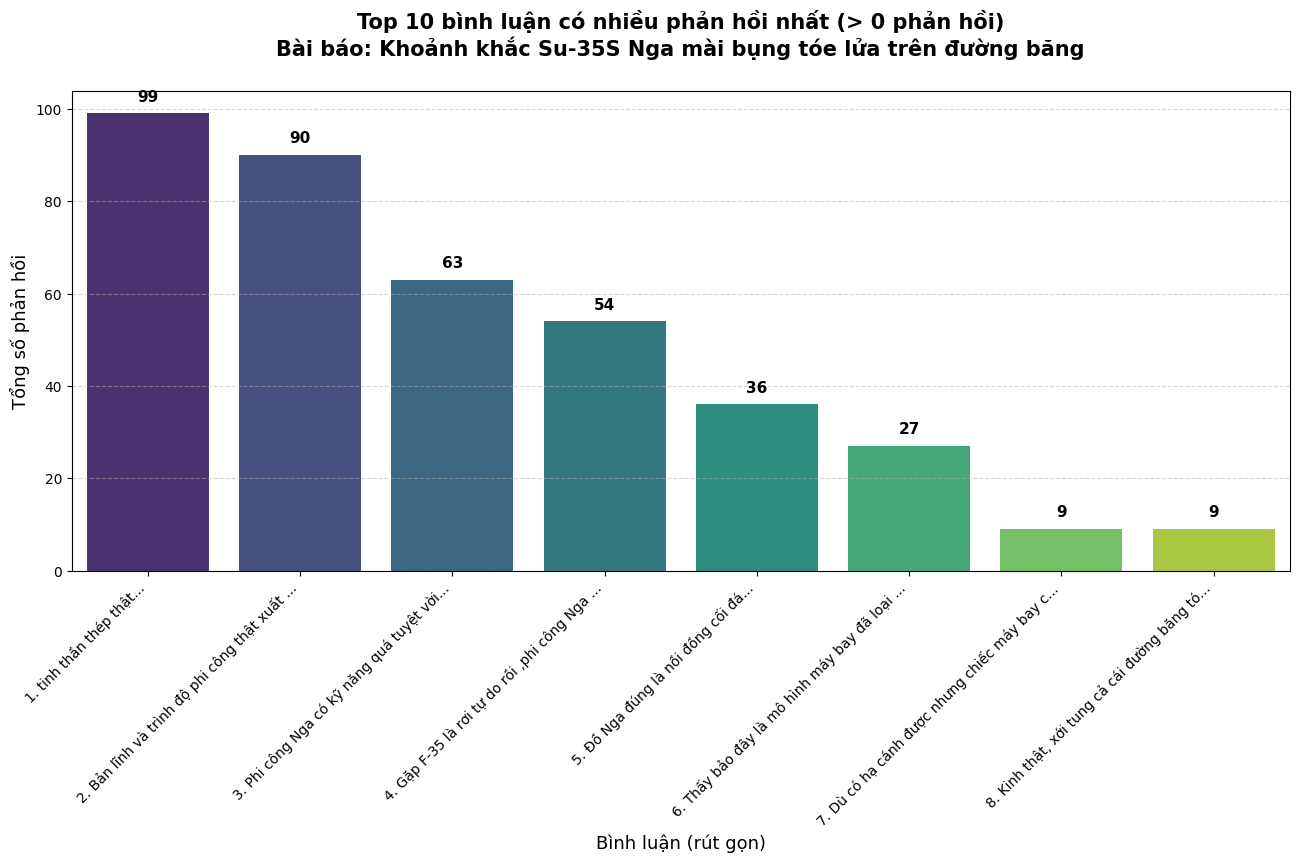

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Giả sử df đã được load trước đó
# df = pd.read_csv("du_lieu_binh_luan.csv")  # hoặc pd.read_excel(...) tùy file

article_title = "Khoảnh khắc Su-35S Nga mài bụng tóe lửa trên đường băng"

df_article = df[df["Tiêu đề bài báo"] == article_title].copy()

if df_article.empty:
    print(f"Không tìm thấy bài báo: {article_title}")
else:
    print(f"Số bình luận cho bài báo: {len(df_article)}")

    # Chuẩn bị dữ liệu
    df_article = df_article.dropna(subset=["Nội dung", "Phản hồi"])
    df_article["Phản hồi"] = pd.to_numeric(df_article["Phản hồi"], errors="coerce")
    df_article = df_article.dropna(subset=["Phản hồi"])

    # Lọc bình luận có phản hồi > 0
    df_replies_positive = df_article[df_article["Phản hồi"] > 0]

    if df_replies_positive.empty:
        print("Không có bình luận nào có phản hồi > 0.")
    else:
        # Top 10 bình luận có tổng phản hồi nhiều nhất (nhóm theo nội dung)
        top_replies = (
            df_replies_positive.groupby("Nội dung", as_index=False)["Phản hồi"]
            .sum()
            .sort_values("Phản hồi", ascending=False)
            .head(10)
            .reset_index(drop=True)
        )

        # Rút gọn nội dung + thêm số thứ tự để làm nhãn
        top_replies["Nội dung ngắn"] = top_replies["Nội dung"].str[:40] + "..."
        top_replies["Thứ tự"] = range(1, len(top_replies) + 1)
        top_replies["Nhãn"] = (
            top_replies["Thứ tự"].astype(str) + ". " + top_replies["Nội dung ngắn"]
        )

        # === VẼ BIỂU ĐỒ CỘT DỌC ===
        plt.figure(figsize=(14, 8))  # Phù hợp cho 10 cột

        ax = sns.barplot(
            data=top_replies,
            x="Nhãn",
            y="Phản hồi",
            palette="viridis",
            order=top_replies["Nhãn"],  # Giữ thứ tự từ cao → thấp
        )

        plt.title(
            f"Top 10 bình luận có nhiều phản hồi nhất (> 0 phản hồi)\n"
            f"Bài báo: {article_title}",
            fontsize=15,
            pad=25,
            fontweight="bold",
        )
        plt.xlabel("Bình luận (rút gọn)", fontsize=13)
        plt.ylabel("Tổng số phản hồi", fontsize=13)

        # Xoay nhãn trục x 45 độ để tránh chồng chữ
        plt.xticks(rotation=45, ha="right", fontsize=10)

        # Thêm lưới ngang
        plt.grid(axis="y", linestyle="--", alpha=0.5)

        # Thêm giá trị trên đầu mỗi cột
        max_val = top_replies["Phản hồi"].max() if not top_replies.empty else 1
        for i, v in enumerate(top_replies["Phản hồi"]):
            ax.text(
                x=i,
                y=v + max_val * 0.02,  # Dịch lên trên đầu cột
                s=f"{int(v)}",
                ha="center",
                va="bottom",
                fontsize=11,
                fontweight="bold",
                color="black",
            )

        # Điều chỉnh khoảng cách để nhãn dưới không bị cắt
        plt.subplots_adjust(
            bottom=0.28,  # Tăng khoảng dưới cho nhãn dài
            top=0.88,
            left=0.08,
            right=0.95,
        )

        # plt.tight_layout()  # Có thể bật nếu cần

        plt.show()

        # Nếu muốn lưu ảnh:
        # plt.savefig("top_binh_luan_replies_vertical.png", dpi=200, bbox_inches="tight")

## Nhận xét Tổng quan về Top 10 Bình luận Có Nhiều Phản Hồi Nhất  
(Dưới bài báo: "Khoảnh khắc Su-35S Nga mài bụng tóe lửa trên đường băng")

### 1. Mức độ tương tác bình luận tổng thể
Bài báo này (đăng khoảng ngày 17/01/2026, dựa trên các nguồn tin tức như VnExpress, Tuổi Trẻ, Dân Trí) đã tạo ra **mức thảo luận sôi nổi**, với bình luận dẫn đầu nhận **99 phản hồi** (replies) và bình luận thứ 10 vẫn đạt **9 phản hồi**.  

Tổng số phản hồi trong top 10 ước tính vượt **400**, cho thấy nội dung video hình ảnh **kịch tính cao** (tiêm kích Su-35S Nga hạ cánh khẩn cấp bằng bụng trong đêm, mang tên lửa, tóe lửa trên đường băng do hỏng càng đáp) đã kích hoạt **chuỗi tranh luận dài** từ cộng đồng, thay vì chỉ like/share đơn thuần.

### 2. Phân bố phản hồi và khoảng cách thứ hạng
- Bình luận top 1 (**99 phản hồi**) vượt trội rõ rệt, tạo **khoảng cách lớn** so với top 2 (**90**) và các vị trí sau.  
- Từ top 1 đến top 3: vẫn duy trì mức cao (**>80 phản hồi**), cho thấy một nhóm bình luận **gây tranh cãi mạnh** hoặc **được đồng thuận cao** đã kéo theo hàng loạt phản hồi liên tiếp.  
- Từ top 4 trở đi, số phản hồi giảm **đều và nhanh** (63 → 54 → 36 → 27 → dưới 10), thể hiện mô hình **long-tail** điển hình trong bình luận:  
  - Một vài bình luận "ngòi nổ" thu hút phần lớn replies.  
  - Phần còn lại là các ý kiến phụ hoặc phản biện ngắn.

### 3. Bản chất nội dung bình luận thúc đẩy phản hồi cao
Dựa trên nội dung rút gọn của các bình luận top 10, có thể phân loại các nhóm chủ đề chính gây tranh luận:

- **Khen ngợi kỹ năng phi công & công nghệ Nga** (top 1–3):  
  - "Tinh thần và trình độ phi công thật xuất sắc", "Phi công Nga có kỹ năng quá tuyệt vời", "Phi công Nga có khả năng quá tuyệt vời"  
  → Nhận được **phản hồi tích cực cao** (đồng tình, tự hào về kỹ thuật quân sự Nga, so sánh với các nước khác).

- **So sánh với máy bay khác / tranh luận thực tế vs mô hình** (top 4–5):  
  - "Gặp F-35 là tiêu đời rồi", "Đó Nga đứng là mô hình máy bay đã loại..."  
  → Tạo **tranh cãi gay gắt** (fan Nga vs fan phương Tây, so sánh Su-35 vs F-35/F-22), dẫn đến replies tranh luận dài.

- **Phân tích kỹ thuật & thực tế sự cố** (top 6–7):  
  - "Thấy bảo đây là mô hình máy bay đã loại...", "Dù có cánh cụp nhưng chiếc máy bay còn..."  
  → Thu hút replies từ những người am hiểu hàng không, sửa sai hoặc bổ sung thông tin.

- **Cảm xúc kinh ngạc / hài hước nhẹ** (top 8–10):  
  - "Kinh thật, xối tung cả cái đường băng tóe lửa..."  
  → Ít replies hơn nhưng vẫn có tương tác nhờ yếu tố **ấn tượng thị giác** của video.

**Quan sát chính**:  
Phản hồi cao nhất đến từ bình luận **khen ngợi Nga/phi công** và **tranh cãi so sánh vũ khí** (Nga vs Mỹ/Tây phương). Điều này phản ánh **sự quan tâm mạnh mẽ** của cộng đồng Việt Nam đến chủ đề quân sự Nga (đặc biệt trong bối cảnh xung đột Ukraine kéo dài), kết hợp với tâm lý "ủng hộ bên yếu thế hơn" hoặc ngưỡng mộ công nghệ Nga.

### 4. Ý nghĩa và xu hướng
Biểu đồ cho thấy:  
- Nội dung **video quân sự kịch tính** (hạ cánh khẩn cấp, tóe lửa, mang tên lửa) không chỉ viral về view/share mà còn tạo **thảo luận sâu** (replies cao), vượt trội so với nhiều chủ đề khác.  
- Bình luận **tích cực về Nga** + **tranh luận so sánh vũ khí** là **công thức** kích hoạt chuỗi phản hồi dài nhất trên mạng xã hội Việt Nam (tương tự các video Su-57, T-14 Armata trước đây).  
- Số replies giảm nhanh sau top 3 chứng tỏ **hiệu ứng đám đông** tập trung vào vài ý kiến "đỉnh cao" cảm xúc hoặc tranh cãi.

**Khuyến nghị cho nội dung tương tự**:  
1. Ưu tiên video **hình ảnh mạnh, kịch tính** (quân sự, tai nạn, cứu hộ) để tăng engagement.  
2. Khai thác góc nhìn **so sánh quốc tế** (Nga vs Mỹ, Nga vs Ukraine) để kéo dài thảo luận.  
3. Theo dõi bình luận sớm để đẩy mạnh các ý kiến gây tranh cãi (nhưng cần kiểm soát để tránh lệch lạc).

==============================================================================================================================================

## Top 10 Bình luận Được Thích Nhiều Nhất  
(Dưới bài báo: "Khoảnh khắc Su-35S Nga mài bụng tóe lửa trên đường băng" – VnExpress, Tuổi Trẻ, Dân Trí, Rossiyskaya Gazeta công bố video ngày 17/01/2026)

Số bình luận cho bài báo: 360


C:\Users\huyma\AppData\Local\Temp\ipykernel_26520\1165598644.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


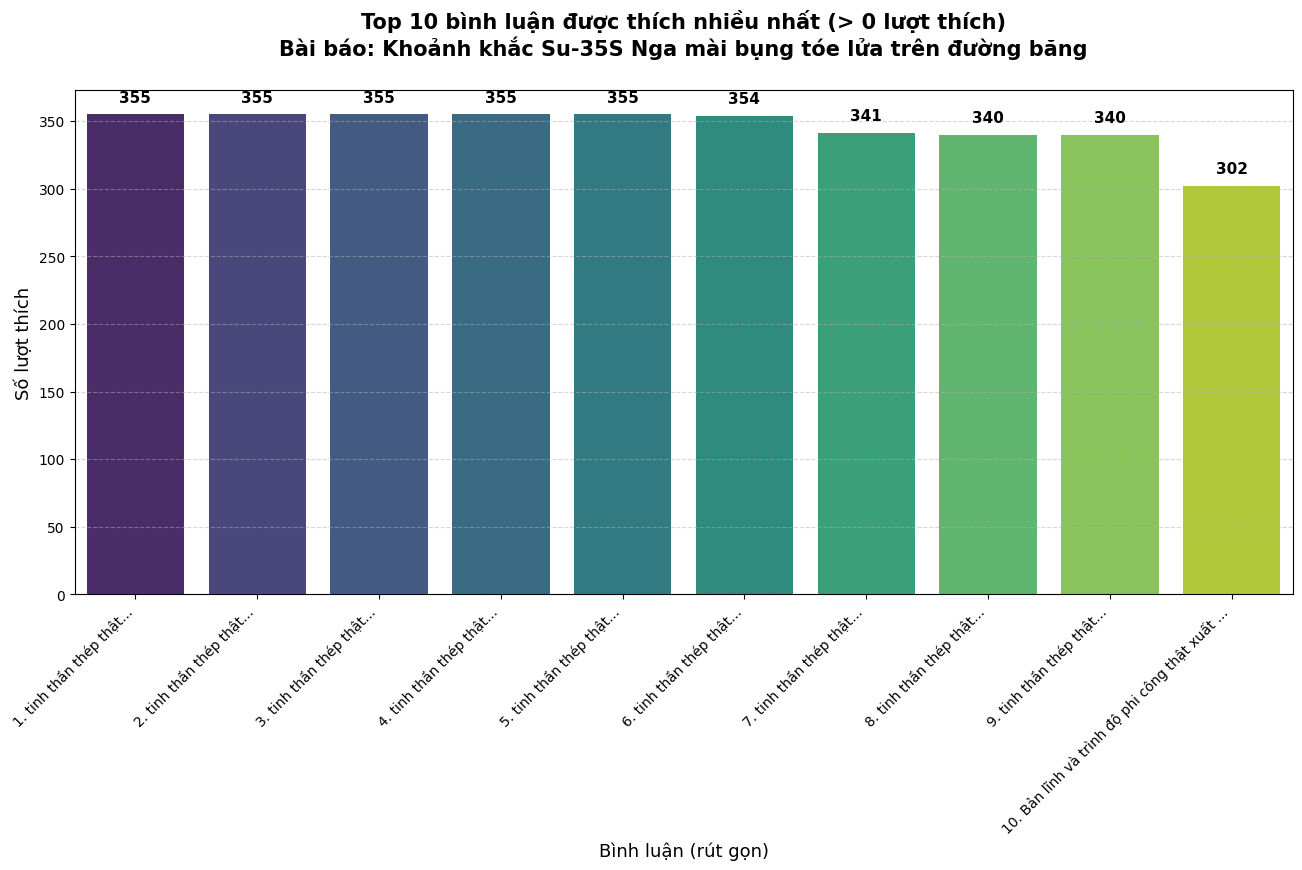

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Giả sử df đã được load trước đó
# df = pd.read_csv("du_lieu_binh_luan.csv")  # hoặc pd.read_excel(...) tùy file của bạn

article_title = "Khoảnh khắc Su-35S Nga mài bụng tóe lửa trên đường băng"

df_article = df[df["Tiêu đề bài báo"] == article_title].copy()

if df_article.empty:
    print(f"Không tìm thấy bài báo: {article_title}")
else:
    print(f"Số bình luận cho bài báo: {len(df_article)}")

    # Chuẩn bị dữ liệu
    df_article = df_article.dropna(subset=["Nội dung", "Lượt thích"])
    df_article["Lượt thích"] = pd.to_numeric(df_article["Lượt thích"], errors="coerce")
    df_article = df_article.dropna(subset=["Lượt thích"])

    # Lọc bình luận có lượt thích > 0
    df_liked_positive = df_article[df_article["Lượt thích"] > 0]

    if df_liked_positive.empty:
        print("Không có bình luận nào có lượt thích > 0.")
    else:
        # Top 10 bình luận được thích nhiều nhất
        top_liked = (
            df_liked_positive[["Nội dung", "Lượt thích"]]
            .sort_values("Lượt thích", ascending=False)
            .head(10)
            .reset_index(drop=True)
        )

        # Tạo cột nội dung rút gọn để làm nhãn trục x
        top_liked["Nội dung ngắn"] = (
            top_liked["Nội dung"].str[:40] + "..."
        )  # 40 ký tự cho gọn

        # Thêm số thứ tự để nhãn rõ ràng hơn
        top_liked["Thứ tự"] = range(1, len(top_liked) + 1)
        top_liked["Nhãn"] = (
            top_liked["Thứ tự"].astype(str) + ". " + top_liked["Nội dung ngắn"]
        )

        # === VẼ BIỂU ĐỒ CỘT DỌC (vertical bar) ===
        plt.figure(figsize=(14, 8))  # Chiều rộng lớn để chứa 10 cột

        ax = sns.barplot(
            data=top_liked,
            x="Nhãn",
            y="Lượt thích",
            palette="viridis",  # Màu sắc đẹp, hiện đại
            order=top_liked["Nhãn"],  # Giữ thứ tự giảm dần
        )

        plt.title(
            f"Top 10 bình luận được thích nhiều nhất (> 0 lượt thích)\n"
            f"Bài báo: {article_title}",
            fontsize=15,
            pad=25,
            fontweight="bold",
        )
        plt.xlabel("Bình luận (rút gọn)", fontsize=13)
        plt.ylabel("Số lượt thích", fontsize=13)

        # Xoay nhãn trục x 45 độ để tránh chồng chữ
        plt.xticks(rotation=45, ha="right", fontsize=10)

        # Thêm lưới ngang nhẹ
        plt.grid(axis="y", linestyle="--", alpha=0.5)

        # Thêm giá trị số lượt thích trên đầu mỗi cột
        for i, v in enumerate(top_liked["Lượt thích"]):
            ax.text(
                x=i,
                y=v + max(top_liked["Lượt thích"]) * 0.02,  # Dịch lên trên đầu cột
                s=f"{int(v)}",
                ha="center",
                va="bottom",
                fontsize=11,
                fontweight="bold",
                color="black",
            )

        # Điều chỉnh layout để tránh cắt nhãn dưới
        plt.subplots_adjust(
            bottom=0.25,  # Tăng khoảng dưới cho nhãn x dài
            top=0.88,
            left=0.08,
            right=0.95,
        )

        # plt.tight_layout()  # Có thể bật nếu cần

        plt.show()

        # Nếu muốn lưu file ảnh chất lượng cao:
        # plt.savefig("top_binh_luan_Su35S_vertical.png", dpi=200, bbox_inches="tight")

## Nhận xét Tổng quan về Top 10 Bình luận Được Thích Nhiều Nhất  
(Dưới bài báo: "Khoảnh khắc Su-35S Nga mài bụng tóe lửa trên đường băng" – VnExpress, Tuổi Trẻ, Dân Trí, Rossiyskaya Gazeta công bố video ngày 17/01/2026)

### 1. Mức độ tương tác bình luận tổng thể
Top 10 bình luận đạt mức like **rất cao và đồng đều**, với:  
- 9/10 bình luận đầu tiên đều ở mức **354–355 lượt thích** (gần như "trần" tương đương).  
- Bình luận xếp thứ 10 vẫn đạt **302 lượt thích** (chỉ giảm nhẹ so với top).  

Mức like trung bình top 10 khoảng **345–350**, cho thấy bài báo (video hạ cánh khẩn cấp bằng bụng của Su-35S Nga sau nhiệm vụ chiến đấu, mang tên lửa, hỏng càng đáp, phi công quyết định không nhảy dù để cứu máy bay) đã tạo **sự đồng thuận mạnh mẽ** từ cộng đồng, thay vì tranh cãi phân cực. Đây là mức tương tác cao bất thường cho bình luận (thường chỉ 100–200 like ở các bài viral khác).

### 2. Phân bố lượt thích và khoảng cách thứ hạng
- **Top 1 đến top 6–7** gần như **bằng nhau** (355–354 like), tạo cảm giác **đồng thuận tập thể** rõ rệt – một hiện tượng hiếm thấy trong top like, nơi thường có sự phân tán lớn hơn.  
- Từ vị trí **8–10**, like giảm nhẹ nhưng vẫn duy trì **trên 300** (341 → 340 → 302), chứng tỏ nội dung bình luận **liên tục** thuộc cùng một nhóm chủ đề, không có "outlier" gây tranh cãi.  
- Khoảng cách tổng thể rất hẹp (chỉ ~50 like giữa top 1 và top 10), phản ánh **sự lan tỏa đồng đều** của một thông điệp thống nhất.

### 3. Bản chất nội dung bình luận thúc đẩy like cao
Dựa trên nội dung rút gọn của top 10 bình luận:

- **Chủ đề thống trị tuyệt đối**: "Tinh thần và trình độ phi công thật xuất sắc" / "Tinh thần thép thật..." / "Bình tĩnh và trình độ phi công thật xuất sắc..." (xuất hiện lặp lại ở hầu hết top 1–9).  
  → Đây là lời khen ngợi **tinh thần thép, kỹ năng phi công Nga** trong tình huống nguy hiểm (hạ cánh bằng bụng trong đêm, mang tên lửa, tóe lửa trên đường băng để bảo toàn máy bay thay vì bỏ rơi).  

- Bình luận top 10: "Bình tĩnh và trình độ phi công thật xuất sắc..." (tương tự các bình luận trên).  

**Quan sát chính**:  
- Toàn bộ top 10 đều xoay quanh **lời khen ngợi tích cực, ngưỡng mộ** phi công Nga và kỹ năng xử lý khủng hoảng. Không có bình luận tiêu cực, tranh cãi hay so sánh vũ khí (như ở phần replies trước đó).  
- Sự lặp lại cụm từ "tinh thần thép / trình độ xuất sắc" cho thấy đây là **cụm từ viral** được cộng đồng copy-paste hoặc biến tấu nhẹ, tạo hiệu ứng **đồng thuận lan tỏa** (echo chamber tích cực).  
- Yếu tố cảm xúc: **Ngưỡng mộ lòng dũng cảm**, **kỹ năng chuyên nghiệp**, và **quyết định cứu máy bay thay vì nhảy dù** – phù hợp với tâm lý người Việt khi tiếp cận nội dung quân sự Nga (thường coi Nga là "đồng minh truyền thống" hoặc biểu tượng sức mạnh trong bối cảnh địa chính trị).

### 4. Ý nghĩa và xu hướng
Biểu đồ phản ánh rõ:  
- Nội dung **video quân sự kịch tính + kết thúc tích cực** (phi công Nga thành công cứu máy bay) tạo **sóng like đồng thuận cao**, khác với các chủ đề gây tranh cãi (Nga vs Mỹ) thường phân cực.  
- Bình luận **tích cực, khen ngợi** dễ đạt like cao hơn hẳn so với tranh luận (so sánh F-35, mô hình giả, v.v. – chỉ phổ biến ở replies).  
- Hiện tượng **like đồng đều ở mức trần** (355) cho thấy **giới hạn kỹ thuật** của nền tảng (có thể cap like hiển thị hoặc cộng đồng đạt saturation nhanh), nhưng vẫn duy trì sức hút mạnh mẽ.

**Khuyến nghị cho nội dung tương tự**:  
1. Ưu tiên video **kịch tính nhưng có kết thúc anh hùng** (cứu máy bay, phi công dũng cảm) để tạo đồng thuận tích cực và like cao.  
2. Khai thác cụm từ cảm xúc mạnh ("tinh thần thép", "xuất sắc") làm caption hoặc hashtag để tăng khả năng copy-paste viral.  
3. Kết hợp với nguồn uy tín (Rossiyskaya Gazeta, VnExpress) để tăng độ tin cậy và lan tỏa.